In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import librosa

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## Locate the dataset

In [2]:
possible_paths = [
    Path("../dataset"),
    Path("dataset"),
    Path(r"D:\\SKIT_Project\\dataset"),
]
DATASET_DIR = next((p.resolve() for p in possible_paths if p.exists()), None)

if DATASET_DIR is None:
    raise FileNotFoundError(
        "Dataset folder not found. Set DATASET_DIR manually to your dataset folder path."
    )

print("Dataset path:", DATASET_DIR)
print("Top-level folders:", [p.name for p in DATASET_DIR.iterdir() if p.is_dir()])

Dataset path: D:\SKIT_Project\dataset
Top-level folders: ['dementia', 'nodementia']


## Read audio files and labels

In [3]:
AUDIO_EXTENSIONS = {".wav", ".mp3", ".flac", ".ogg", ".m4a", ".aac"}
CLASS_NAMES = {
    "dementia": "dementia",
    "nodementia": "nodementia",
    "no_dementia": "nodementia",
    "non-dementia": "nodementia",
    "non_dementia": "nodementia",
}

audio_records = []
for class_dir in DATASET_DIR.iterdir():
    if not class_dir.is_dir():
        continue
    folder_key = class_dir.name.strip().lower().replace(" ", "")
    label = CLASS_NAMES.get(folder_key)
    if label is None:
        # Try a few common folder-name variants
        normalized = class_dir.name.strip().lower().replace(" ", "").replace("_", "").replace("-", "")
        if normalized == "dementia":
            label = "dementia"
        elif normalized in {"nodementia", "nondementia"}:
            label = "nodementia"
    if label is None:
        continue

    for file_path in class_dir.rglob("*"):
        if file_path.is_file() and file_path.suffix.lower() in AUDIO_EXTENSIONS:
            audio_records.append({"path": file_path, "label": label})

audio_df = pd.DataFrame(audio_records)
if audio_df.empty:
    raise ValueError(
        "No audio files found. Check folder names and file extensions. "
        "Expected dementia and nodementia class folders."
    )

print("Total audio files:", len(audio_df))
display(audio_df.groupby("label").size().rename("file_count").to_frame())
display(audio_df.head())

Total audio files: 360


,file_count
label,
dementia,131
nodementia,229


,path,label
0,D:\SKIT_Project\dataset\dementia\Abe Burrows\A...,dementia
1,D:\SKIT_Project\dataset\dementia\Aileen Hernan...,dementia
2,D:\SKIT_Project\dataset\dementia\Aileen Hernan...,dementia
3,D:\SKIT_Project\dataset\dementia\Aileen Hernan...,dementia
4,D:\SKIT_Project\dataset\dementia\Alan Ramsey\a...,dementia


## Extract MFCC summary features
MFCCs represent aspects of the short-term spectral shape of audio. For each file, this notebook calculates the mean and standard deviation of each MFCC coefficient over time, giving a fixed-length feature vector.

In [4]:
def extract_mfcc_features(file_path, n_mfcc=13):
    try:
        signal, sr = librosa.load(file_path, sr=16000, mono=True)
        if signal.size == 0:
            raise ValueError("Empty audio")
        mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=n_mfcc)
        features = {}
        for i in range(n_mfcc):
            features[f"mfcc_{i+1}_mean"] = float(np.mean(mfcc[i]))
            features[f"mfcc_{i+1}_std"] = float(np.std(mfcc[i]))
        features["duration_seconds"] = float(librosa.get_duration(y=signal, sr=sr))
        features["rms_mean"] = float(np.mean(librosa.feature.rms(y=signal)))
        features["zcr_mean"] = float(np.mean(librosa.feature.zero_crossing_rate(signal)))
        return features, None
    except Exception as exc:
        return None, str(exc)

feature_rows = []
failed_files = []

for row in audio_df.itertuples(index=False):
    features, error = extract_mfcc_features(row.path)
    if features is None:
        failed_files.append({"path": str(row.path), "error": error})
        continue
    features["path"] = str(row.path)
    features["label"] = row.label
    feature_rows.append(features)

features_df = pd.DataFrame(feature_rows)
failed_df = pd.DataFrame(failed_files)

print("Successfully processed:", len(features_df))
print("Failed files:", len(failed_df))
if not failed_df.empty:
    display(failed_df.head())

if features_df.empty:
    raise ValueError("No audio features were extracted successfully.")

display(features_df.head())

Successfully processed: 360
Failed files: 0


,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,mfcc_5_mean,mfcc_5_std,...,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,duration_seconds,rms_mean,zcr_mean,path,label
0,-290.894226,90.324074,103.325874,40.952290,31.520834,27.468496,18.506176,24.015102,8.285114,17.901567,...,9.639206,3.368045,10.388342,-5.722221,11.232134,71.019688,0.042058,0.102158,D:\SKIT_Project\dataset\dementia\Abe Burrows\A...,dementia
1,-332.609802,80.299843,119.011658,42.997719,2.573827,32.044609,18.508610,22.891491,-3.082855,17.222090,...,10.582289,-9.440688,9.598793,5.068859,9.860040,47.000000,0.037931,0.104126,D:\SKIT_Project\dataset\dementia\Aileen Hernan...,dementia
2,-210.087753,119.215401,68.219551,46.933098,1.398461,29.873440,13.520696,24.507381,1.728840,19.050022,...,11.535592,-11.186091,11.773222,-5.553871,10.998050,38.000000,0.074112,0.142498,D:\SKIT_Project\dataset\dementia\Aileen Hernan...,dementia
3,-338.254486,84.265968,126.706917,42.934311,15.690623,33.033348,-8.187231,26.539669,10.898719,21.172417,...,10.341165,-9.548878,9.538286,-2.497692,8.797155,90.000000,0.031270,0.103313,D:\SKIT_Project\dataset\dementia\Aileen Hernan...,dementia
4,-361.912262,105.808426,96.568855,54.680119,2.274842,27.184465,36.884491,28.228430,4.056905,17.687374,...,13.294925,-4.440179,10.911772,-7.837333,10.456482,55.000000,0.018489,0.126244,D:\SKIT_Project\dataset\dementia\Alan Ramsey\a...,dementia


## Prepare X and y

In [5]:
metadata = features_df[["path", "label"]].copy()
X = features_df.drop(columns=["path", "label"])
y = features_df["label"].map({"nodementia": 0, "dementia": 1})

if y.isna().any():
    raise ValueError("Unexpected label found. Check the class-folder mapping.")

print("Feature matrix shape:", X.shape)
print("Labels:")
display(y.map({0: "nodementia", 1: "dementia"}).value_counts().to_frame("count"))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Feature matrix shape: (360, 29)
Labels:


,count
label,
nodementia,229
dementia,131


Training samples: 270
Test samples: 90


## Train baseline models and compare performance

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE
        ))
    ]),
    "SVM (RBF)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", class_weight="balanced"))
    ]),
}

results = []
fitted_models = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    fitted_models[model_name] = model
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1-score
0,SVM (RBF),0.700,0.600,0.545,0.571
1,Random Forest,0.700,0.607,0.515,0.557
2,Logistic Regression,0.567,0.425,0.515,0.466


## Inspect classification reports and confusion matrices

\n======================================================================
Logistic Regression
              precision    recall  f1-score   support

 No Dementia       0.68      0.60      0.64        57
    Dementia       0.42      0.52      0.47        33

    accuracy                           0.57        90
   macro avg       0.55      0.56      0.55        90
weighted avg       0.59      0.57      0.57        90



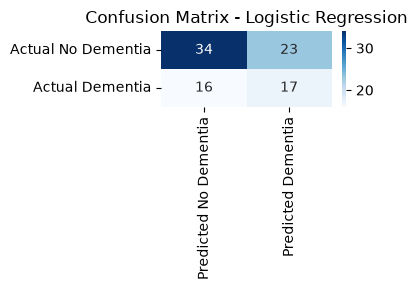

\n======================================================================
Random Forest
              precision    recall  f1-score   support

 No Dementia       0.74      0.81      0.77        57
    Dementia       0.61      0.52      0.56        33

    accuracy                           0.70        90
   macro avg       0.67      0.66      0.67        90
weighted avg       0.69      0.70      0.69        90



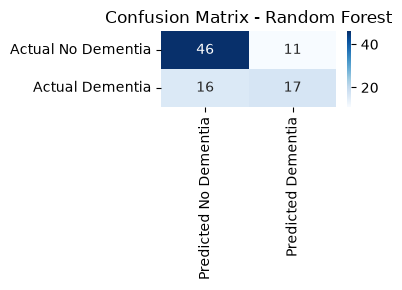

\n======================================================================
SVM (RBF)
              precision    recall  f1-score   support

 No Dementia       0.75      0.79      0.77        57
    Dementia       0.60      0.55      0.57        33

    accuracy                           0.70        90
   macro avg       0.68      0.67      0.67        90
weighted avg       0.69      0.70      0.70        90



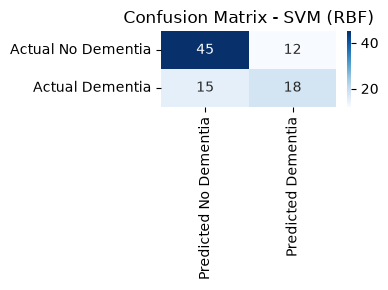

In [7]:
for model_name, model in fitted_models.items():
    y_pred = model.predict(X_test)
    print("\\n" + "=" * 70)
    print(model_name)
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["No Dementia", "Dementia"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    plt.figure(figsize=(4, 3))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Predicted No Dementia", "Predicted Dementia"],
        yticklabels=["Actual No Dementia", "Actual Dementia"]
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

## Save results and extracted features

In [8]:
OUTPUT_DIR = Path("analysis_output")
OUTPUT_DIR.mkdir(exist_ok=True)

features_df.to_csv(OUTPUT_DIR / "baseline_audio_features.csv", index=False)
results_df.to_csv(OUTPUT_DIR / "baseline_model_comparison.csv", index=False)
if not failed_df.empty:
    failed_df.to_csv(OUTPUT_DIR / "failed_audio_files.csv", index=False)

print("Saved files to:", OUTPUT_DIR.resolve())
print(" - baseline_audio_features.csv")
print(" - baseline_model_comparison.csv")
if not failed_df.empty:
    print(" - failed_audio_files.csv")

Saved files to: D:\SKIT_Project\notebooks\analysis_output
 - baseline_audio_features.csv
 - baseline_model_comparison.csv
